# SVA-Agent: đánh giá E0–E6, U2

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

sys.path.insert(0, str(Path.cwd().parent / "src"))

from sva.config import RESULTS_DIR, TASK_IDS
from sva.eval import accuracy, correct, load_predictions

BLUE, ORANGE, AQUA, GRAY, DARK = "#2a78d6", "#eb6834", "#1baf7a", "#b5b4ae", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 90})
R = lambda name: json.loads((RESULTS_DIR / "agent" / f"{name}.json").read_text(encoding="utf-8"))
display(Markdown((RESULTS_DIR / "tables" / "agent_test.md").read_text(encoding="utf-8")))

# SVA-Agent: kết quả đánh giá (bản 3B, tập test)

## E0 · Chế độ benchmark, giấu tên task

| Task | n | task đoán đúng | SVA (biết task) | SVA-Agent (tự đoán) | dự đoán trùng | b / c |
|---|---|---|---|---|---|---|
| q8 | 280 | 100.0% | 58,9 | 58,9 | 100.0% | 0 / 0 |
| q9 | 280 | 100.0% | 78,9 | 78,9 | 100.0% | 0 / 0 |
| q10 | 700 | 100.0% | 87,1 | 87,1 | 100.0% | 0 / 0 |
| q11 | 700 | 100.0% | 74,3 | 74,3 | 100.0% | 0 / 0 |
| q13 | 490 | 100.0% | 46,5 | 46,5 | 100.0% | 0 / 0 |
| q14 | 192 | 100.0% | 60,4 | 60,4 | 100.0% | 0 / 0 |

## E0 / E1 · Định tuyến

| cách | dev | test |
|---|---|---|
| luat (so clip that) | 100.00% (1134/1134) | 100.00% (2642/2642) |
| luat (1 video) | 100.00% (1134/1134) | 100.00% (2642/2642) |
| chi LLM | 98.32% (1115/1134) | 98.11% (2592/2642) |
| luat + LLM | 100.00% (1134/1134) | 100.00% (2642/2642) |

Câu ngoài phạm vi (30 câu tự viết): Question Agent từ chối đúng **22/30**; chỉ luật thì 28/30 câu không khớp luật nào.

## E1 · Câu hỏi viết lại (LLM viết lại, 40 câu test mỗi task)

| Task | định tuyến đúng | đúng (câu gốc) | đúng (câu viết lại) |
|---|---|---|---|
| q8 | 100.0% | 57,5 | 57,5 |
| q9 | 100.0% | 80,0 | 80,0 |
| q10 | 100.0% | 90,0 | 90,0 |
| q11 | 100.0% | 75,0 | 75,0 |
| q13 | 97.5% | 47,5 | 42,5 |
| q14 | 100.0% | 65,0 | 67,5 |

## E2 · Chế độ Open (không cho thấy phương án)

| Task | n | MCQ (cùng câu) | Open kiểu paper (ánh xạ vào phương án) | Open kiểu chặt (khớp đáp án mở) | b / c (MCQ vs Open) |
|---|---|---|---|---|---|
| q8 | 280 | 58,9 | 51,1 | 9,3 | 32 / 54 |
| q9 | 280 | 78,9 | 78,9 | 78,9 | 0 / 0 |
| q10 | 700 | 87,1 | 74,7 | 64,9 | 18 / 105 |
| q11 | 200 | 77,0 | 57,0 | sự kiện khớp 32,0, ROUGE-L 0.16 | 17 / 57 |
| q13 | 490 | 46,5 | 45,1 | 32,0 | 47 / 54 |
| q14 | 192 | 60,4 | 67,2 | 66,1 | 20 / 7 |

## E3 · Video dài (ghép từ clip test, câu hỏi kèm mốc thời gian)

| Task | n | đúng (clip gốc, cắt sẵn) | đúng (video dài, agent tự tìm đoạn) | IoU đoạn | trạng thái |
|---|---|---|---|---|---|
| q8 | 100 | 62,0 | 56,0 | 0.87 | answered 100 |
| q9 | 25 | 76,0 | 60,0 | — | answered 25 |
| q10 | 100 | 77,0 | 78,0 | 0.99 | answered 100 |
| q11 | 60 | 76,7 | 76,7 | 1.00 | answered 60 |
| q13 | 100 | 39,0 | 43,0 | 0.99 | answered 100 |
| q14 | 30 | 63,3 | 70,0 | — | answered 30 |

## E4 · Định dạng video khác (40 clip test mỗi task)

| Task | gốc | fps ×2 | 1280×720 | thêm bảng tỉ số / logo | cắt dọc 9:16 |
|---|---|---|---|---|---|
| q8 | 57,5 | 60,0 | 60,0 | 57,5 | 60,0 |
| q10 | 92,5 | 90,0 | 90,0 | 90,0 | 35,0 |

## E6 · Biết từ chối

Ngưỡng xác suất **0.527** chọn trên dev (mục tiêu đúng ≥ 85% trên câu trả lời).

| | trả lời (% câu) | đúng trên câu trả lời | đúng nếu trả lời hết |
|---|---|---|---|
| dev | 64,8 | 85,2 | 72,1 |
| test | 65,5 | 82,5 | 70,4 |

## U2 · Reasoner: luật hay LLM ra quyết định

| Task | dev luật | dev LLM | test luật | test LLM | b / c (test) | số bước TB (LLM, test) |
|---|---|---|---|---|---|---|
| q8 | 67,5 | 62,5 | 58,9 | 61,1 | 21 / 15 | 2,3 |
| q13 | 45,7 | 46,2 | 46,5 | 47,6 | 22 / 17 | 2,1 |



## 1. E0 · Giấu tên task

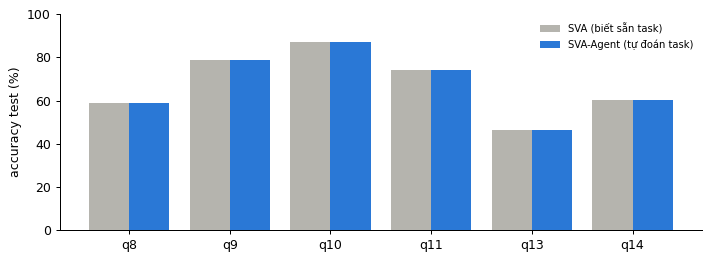

ty le du doan trung nhau: {'q8': '100.0%', 'q9': '100.0%', 'q10': '100.0%', 'q11': '100.0%', 'q13': '100.0%', 'q14': '100.0%'}


In [2]:
fig, ax = plt.subplots(figsize=(8, 3))
x = np.arange(len(TASK_IDS))
old = [100 * accuracy(load_predictions("sva", t, "test")) for t in TASK_IDS]
new = [100 * accuracy(load_predictions("sva_agent", t, "test")) for t in TASK_IDS]
ax.bar(x - 0.2, old, 0.4, color=GRAY, label="SVA (biết sẵn task)")
ax.bar(x + 0.2, new, 0.4, color=BLUE, label="SVA-Agent (tự đoán task)")
ax.set_xticks(x, TASK_IDS); ax.set_ylim(0, 100); ax.set_ylabel("accuracy test (%)"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
same = [np.mean([a["pred"] == b["pred"] for a, b in zip(sorted(load_predictions("sva_agent", t, "test"), key=lambda r: r["index"]),
                                                          sorted(load_predictions("sva", t, "test"), key=lambda r: r["index"]))])
        for t in TASK_IDS]
print("ty le du doan trung nhau:", {t: f"{100 * s:.1f}%" for t, s in zip(TASK_IDS, same)})

## 2. E2 · Chế độ Open so với trắc nghiệm

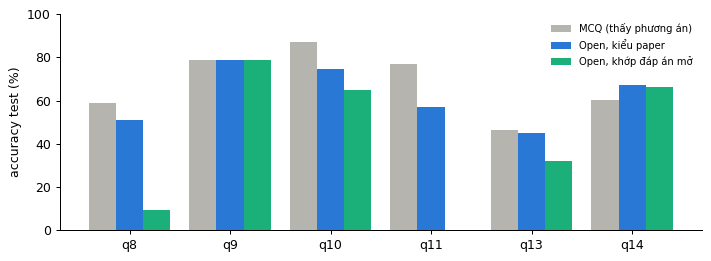

In [3]:
o = R("open")
ts = list(o)
fig, ax = plt.subplots(figsize=(8, 3))
x = np.arange(len(ts))
ax.bar(x - 0.27, [o[t]["mcq"] for t in ts], 0.27, color=GRAY, label="MCQ (thấy phương án)")
ax.bar(x, [o[t]["open_paper"] for t in ts], 0.27, color=BLUE, label="Open, kiểu paper")
ax.bar(x + 0.27, [o[t].get("open_strict", np.nan) for t in ts], 0.27, color=AQUA, label="Open, khớp đáp án mở")
ax.set_xticks(x, ts); ax.set_ylim(0, 100); ax.set_ylabel("accuracy test (%)"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 3. E3, E4 · Video dài và định dạng khác

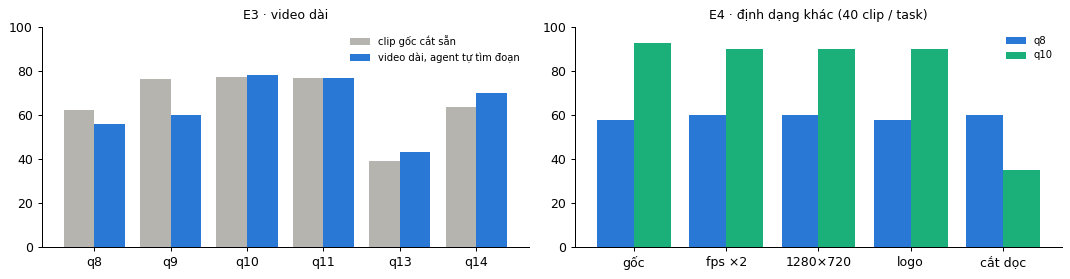

In [4]:
lg, fm = R("long"), R("format")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
ts = [t for t in ("q8", "q9", "q10", "q11", "q13", "q14") if any(r["task"] == t for r in lg)]
x = np.arange(len(ts))
axes[0].bar(x - 0.2, [100 * np.mean([r["old_correct"] for r in lg if r["task"] == t]) for t in ts], 0.4, color=GRAY, label="clip gốc cắt sẵn")
axes[0].bar(x + 0.2, [100 * np.mean([r["correct"] for r in lg if r["task"] == t]) for t in ts], 0.4, color=BLUE, label="video dài, agent tự tìm đoạn")
axes[0].set_xticks(x, ts); axes[0].set_ylim(0, 100); axes[0].legend(frameon=False, fontsize=8); axes[0].set_title("E3 · video dài", fontsize=10)
kinds = ["orig", "fps50", "hd720", "overlay", "portrait"]
for j, t in enumerate(("q8", "q10")):
    rows = [r for r in fm if r["task"] == t]
    axes[1].bar(np.arange(len(kinds)) + (j - 0.5) * 0.4, [100 * np.mean([r[k] for r in rows]) for k in kinds], 0.4,
                color=[BLUE, AQUA][j], label=t)
axes[1].set_xticks(range(len(kinds)), ["gốc", "fps ×2", "1280×720", "logo", "cắt dọc"]); axes[1].set_ylim(0, 100)
axes[1].legend(frameon=False, fontsize=8); axes[1].set_title("E4 · định dạng khác (40 clip / task)", fontsize=10)
plt.tight_layout(); plt.show()

## 4. E6 · Biết từ chối

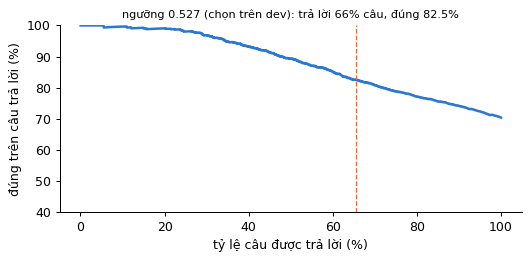

In [5]:
a = R("abstain")
pool = sorted([(max(r["dist"].values()), correct(r)) for t in TASK_IDS for r in load_predictions("sva_agent", t, "test")], reverse=True)
cov = np.arange(1, len(pool) + 1) / len(pool)
acc = np.cumsum([c for _, c in pool]) / np.arange(1, len(pool) + 1)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(100 * cov, 100 * acc, color=BLUE, lw=2)
ax.axvline(a["test"]["coverage"], color=ORANGE, ls="--", lw=1)
ax.set_xlabel("tỷ lệ câu được trả lời (%)"); ax.set_ylabel("đúng trên câu trả lời (%)"); ax.set_ylim(40, 100)
ax.set_title(f"ngưỡng {a['threshold']} (chọn trên dev): trả lời {a['test']['coverage']:.0f}% câu, đúng {a['test']['acc_answered']:.1f}%", fontsize=9)
plt.tight_layout(); plt.show()